<a href="https://colab.research.google.com/github/jatinkumar-creator/machine-learning-portfolio/blob/main/05_Classification/notebooks/04_Decision_Tree_Hyperparameters_and_Pruning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
#Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris

from sklearn.model_selection import (
    train_test_split,
    GridSearchCV
)

from sklearn.tree import (
    DecisionTreeClassifier,
    plot_tree
)

from sklearn.metrics import (
    accuracy_score,
    classification_report
)

In [2]:
#Load the dataset
iris = load_iris()

X = iris.data
y = iris.target

print("Features:", iris.feature_names)
print("Classes:", iris.target_names)
print("Dataset shape:", X.shape)

Features: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Classes: ['setosa' 'versicolor' 'virginica']
Dataset shape: (150, 4)


In [3]:
#Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 120
Testing samples: 30


In [4]:
#Train a default Decision Tree
default_model = DecisionTreeClassifier(
    random_state=42
)

default_model.fit(X_train, y_train)

train_predictions = default_model.predict(X_train)
test_predictions = default_model.predict(X_test)

print(
    "Training Accuracy:",
    accuracy_score(y_train, train_predictions)
)

print(
    "Testing Accuracy:",
    accuracy_score(y_test, test_predictions)
)

Training Accuracy: 1.0
Testing Accuracy: 0.9333333333333333


In [5]:
#Experiment with max_depth
depth_values = [1, 2, 3, 4, 5, 10, None]

depth_results = []

for depth in depth_values:

    model = DecisionTreeClassifier(
        max_depth=depth,
        random_state=42
    )

    model.fit(X_train, y_train)

    train_accuracy = model.score(X_train, y_train)
    test_accuracy = model.score(X_test, y_test)

    depth_results.append({
        "Max Depth": str(depth),
        "Training Accuracy": train_accuracy,
        "Testing Accuracy": test_accuracy
    })

depth_df = pd.DataFrame(depth_results)

depth_df

,Max Depth,Training Accuracy,Testing Accuracy
0,1,0.666667,0.666667
1,2,0.966667,0.933333
2,3,0.983333,0.966667
3,4,0.991667,0.933333
4,5,1.000000,0.933333
5,10,1.000000,0.933333
6,None,1.000000,0.933333


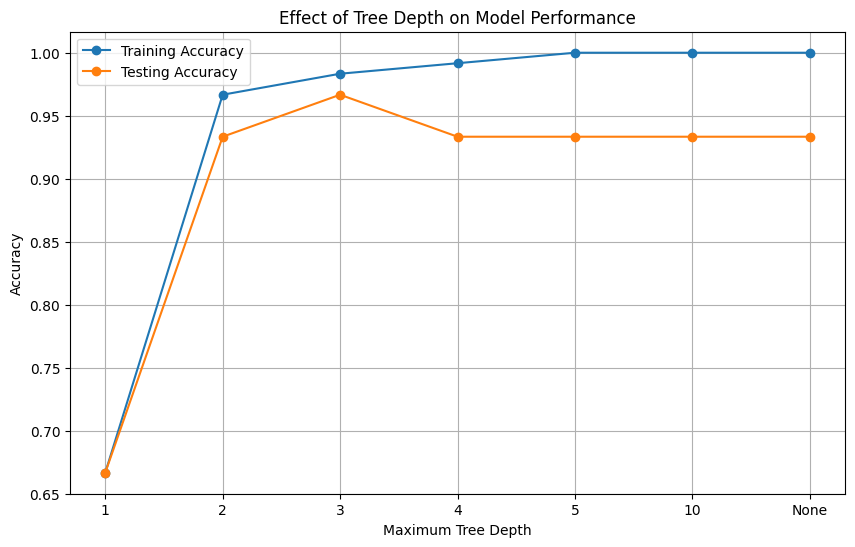

In [6]:
#Visualize the effect of tree depth
plt.figure(figsize=(10, 6))

plt.plot(
    depth_df["Max Depth"],
    depth_df["Training Accuracy"],
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    depth_df["Max Depth"],
    depth_df["Testing Accuracy"],
    marker="o",
    label="Testing Accuracy"
)

plt.xlabel("Maximum Tree Depth")
plt.ylabel("Accuracy")

plt.title("Effect of Tree Depth on Model Performance")

plt.legend()
plt.grid(True)

plt.show()

In [7]:
#Experiment with min_samples_split
split_values = [2, 5, 10, 20]

split_results = []

for value in split_values:

    model = DecisionTreeClassifier(
        min_samples_split=value,
        random_state=42
    )

    model.fit(X_train, y_train)

    split_results.append({
        "Min Samples Split": value,
        "Training Accuracy": model.score(X_train, y_train),
        "Testing Accuracy": model.score(X_test, y_test)
    })

pd.DataFrame(split_results)

,Min Samples Split,Training Accuracy,Testing Accuracy
0,2,1.000000,0.933333
1,5,0.983333,0.966667
2,10,0.983333,0.966667
3,20,0.983333,0.966667


In [8]:
#Visualize the effect of Gini and Entropy
criteria = ["gini", "entropy"]

criterion_results = []

for criterion in criteria:

    model = DecisionTreeClassifier(
        criterion=criterion,
        random_state=42
    )

    model.fit(X_train, y_train)

    criterion_results.append({
        "Criterion": criterion,
        "Training Accuracy": model.score(X_train, y_train),
        "Testing Accuracy": model.score(X_test, y_test),
        "Tree Depth": model.get_depth(),
        "Leaf Nodes": model.get_n_leaves()
    })

pd.DataFrame(criterion_results)

,Criterion,Training Accuracy,Testing Accuracy,Tree Depth,Leaf Nodes
0,gini,1.0,0.933333,5,8
1,entropy,1.0,0.933333,5,8


In [9]:
#Understand the pruning path
initial_tree = DecisionTreeClassifier(
    random_state=42
)

initial_tree.fit(X_train, y_train)

path = initial_tree.cost_complexity_pruning_path(
    X_train,
    y_train
)

ccp_alphas = path.ccp_alphas

print("Candidate alpha values:")
print(ccp_alphas)

Candidate alpha values:
[0.         0.00625    0.00811404 0.03392857 0.27067669 0.33333333]


In [10]:
#Train trees with different ccp_alpha values
pruning_results = []

for alpha in ccp_alphas:

    model = DecisionTreeClassifier(
        random_state=42,
        ccp_alpha=alpha
    )

    model.fit(X_train, y_train)

    pruning_results.append({
        "Alpha": alpha,
        "Training Accuracy": model.score(X_train, y_train),
        "Testing Accuracy": model.score(X_test, y_test),
        "Tree Depth": model.get_depth(),
        "Leaf Nodes": model.get_n_leaves()
    })

pruning_df = pd.DataFrame(pruning_results)

pruning_df.round(4)

,Alpha,Training Accuracy,Testing Accuracy,Tree Depth,Leaf Nodes
0,0.0000,1.0000,0.9333,5,8
1,0.0062,0.9917,0.9667,4,6
2,0.0081,0.9833,0.9667,3,4
3,0.0339,0.9667,0.9333,2,3
4,0.2707,0.6667,0.6667,1,2
5,0.3333,0.3333,0.3333,0,1


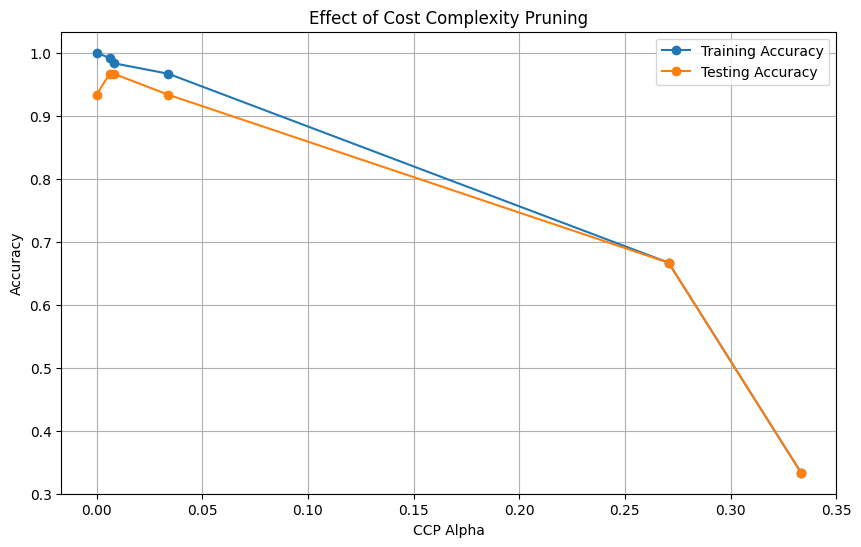

In [11]:
#Visualize pruning
plt.figure(figsize=(10, 6))

plt.plot(
    pruning_df["Alpha"],
    pruning_df["Training Accuracy"],
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    pruning_df["Alpha"],
    pruning_df["Testing Accuracy"],
    marker="o",
    label="Testing Accuracy"
)

plt.xlabel("CCP Alpha")
plt.ylabel("Accuracy")

plt.title("Effect of Cost Complexity Pruning")

plt.legend()
plt.grid(True)

plt.show()

In [12]:
#Optimize using GridSearchCV
param_grid = {
    "max_depth": [2, 3, 4, 5, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "criterion": ["gini", "entropy"]
}

grid_search = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

GridSearchCV(cv=5, estimator=DecisionTreeClassifier(random_state=42), n_jobs=-1,
             param_grid={'criterion': ['gini', 'entropy'],
                         'max_depth': [2, 3, 4, 5, None],
                         'min_samples_leaf': [1, 2, 4],
                         'min_samples_split': [2, 5, 10]},
             scoring='accuracy')

In [13]:
#Find the best hyperparameters
print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-validation Accuracy:")
print(grid_search.best_score_)

Best Parameters:
{'criterion': 'gini', 'max_depth': 4, 'min_samples_leaf': 1, 'min_samples_split': 2}

Best Cross-validation Accuracy:
0.9416666666666668


In [14]:
#Final test evaluation
best_model = grid_search.best_estimator_

final_predictions = best_model.predict(X_test)

print(
    "Final Test Accuracy:",
    accuracy_score(y_test, final_predictions)
)

print(
    classification_report(
        y_test,
        final_predictions,
        target_names=iris.target_names
    )
)

Final Test Accuracy: 0.9333333333333333
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



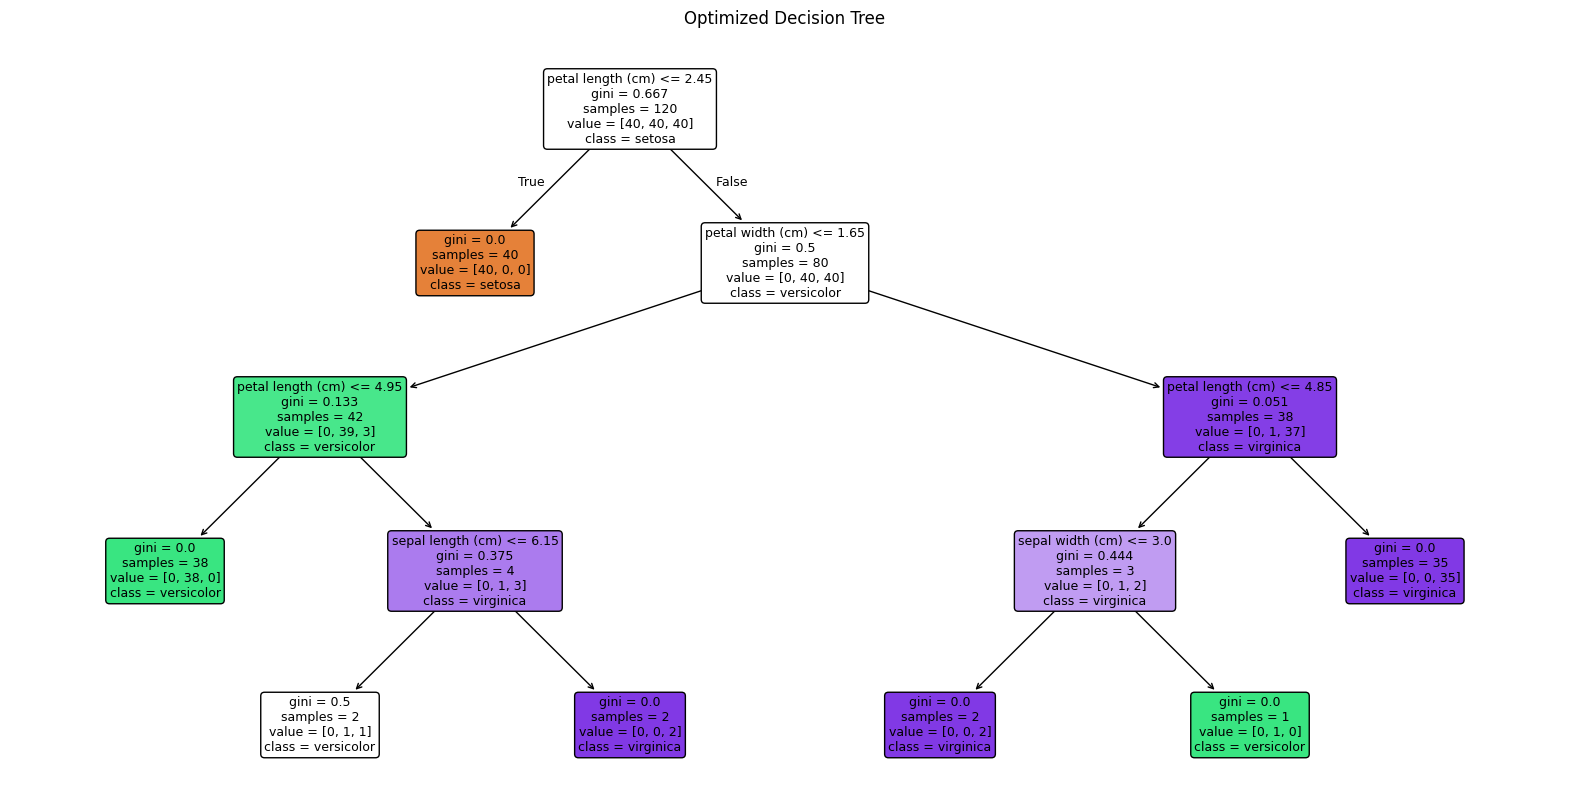

In [15]:
#Visualize the optimized tree
plt.figure(figsize=(20, 10))

plot_tree(
    best_model,
    feature_names=iris.feature_names,
    class_names=iris.target_names,
    filled=True,
    rounded=True,
    fontsize=9
)

plt.title("Optimized Decision Tree")

plt.show()